<a href="https://colab.research.google.com/github/KruthikaVirupakshappa/DATA266-Lab1-Pair37/blob/jiayi-work/task1_llm/jiayi/src/Task1_GPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import json
from pathlib import Path

MEMBER_NAME = "jiayi"
config_path = Path("task1_llm") / MEMBER_NAME / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

SID4         = 4253  # last four digits of your SJSU ID
SEED         = config["seed"] # torch.manual_seed, np.random.seed, random_state
SLICE        = SID4 % 1000   # start index of your dataset subset
HP_ID        = SID4 % 6      # your assigned hyperparameter arm, Table 0.1
CLS_A, CLS_B = (SID4 % 10), ((SID4 // 10) % 10)   # your two focus classes

train_size = config["data"]["train_size"]
val_size = config["data"]["val_size"]
seq_len = config["data"]["seq_len"]

d_model = config["model"]["d_model"]
num_heads = config["model"]["num_heads"]
num_layers = config["model"]["num_layers"]

batch_size = config["training"]["batch_size"]
epochs = config["training"]["epochs"]
optimizer_name = config["training"]["optimizer"]
base_lr = config["training"]["base_lr"]
warmup_fraction = config["training"]["warmup_fraction"]
min_lr_ratio = config["training"]["min_lr_ratio"]

generation_prompt = config["generation"]["prompt"]
generation_max_new = config["generation"]["max_new"]
generation_temperatures = config["generation"]["temperatures"]

In [7]:
print(f"SID4: {SID4}, SEED: {SEED}, SLICE: {SLICE}, HP_ID: {HP_ID}, CLS_A, CLS_B: {CLS_A}, {CLS_B}")

SID4: 4253, SEED: 4253, SLICE: 253, HP_ID: 5, CLS_A, CLS_B: 3, 5


## Task 1
### data preparation

In [54]:
import random
import numpy as np
import torch
from pathlib import Path
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
import math
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
from datetime import datetime
import platform
from zoneinfo import ZoneInfo
import subprocess
import sys
from tqdm.auto import tqdm
import re
import pandas as pd

In [9]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [11]:
# load shared data from download_tinystories.py
from datasets import load_from_disk
from pathlib import Path
from datasets import load_dataset

dataset_folder = Path("task1_llm/data/tinystories")
data = load_from_disk(str(dataset_folder))

# inspect the original dataset
print(data)
print(data.keys())

# only use the original training set for training and validation
original_train = data["train"]

# use SEED to randomize original_train
shuffled_train = original_train.shuffle(seed=SEED)

# split the shuffled train
my_train = shuffled_train.select(range(train_size))
my_val = shuffled_train.select(range(train_size, train_size + val_size))

# inspect the splitted dataset by checking shape and a few data
print(len(my_train))
print(len(my_val))
print(my_train.column_names)
print(my_train[0])
print(my_val[0])


DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})
dict_keys(['train', 'validation'])
100000
10000
['text']
{'text': 'Once upon a time, there was a little bird named Blue. Blue was very fast and loved to fly high in the sky. One day, Blue met a little girl named Lily. \n\n"Hello, Blue! You can fly very fast!" said Lily. \n\n"Yes, I can fly very fast!" replied Blue, happily. \n\nBut then, a big storm came and Blue got lost. Blue was scared and didn\'t know what to do. \n\n"Can you help me, Lily?" asked Blue. \n\n"Yes, I can help you!" said Lily. "Let\'s look for your history book. Maybe it will help us find your way home." \n\nSo, Lily and Blue searched for Blue\'s history book. They found it and read about all the places Blue had flown before. They followed the book and finally, Blue found his way home. \n\n"Thank you, Lily! You\'re my hero!" said Blue. \

In [12]:
train_text = "\n".join(my_train["text"])
val_text = "\n".join(my_val["text"])

chars = sorted(list(set(train_text)))
vocab_size = len(chars)

char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for ch, i in char_to_idx.items()}

def encode(s):
    return [char_to_idx[c] for c in s]

def decode(ids):
    return "".join(idx_to_char[i] for i in ids)

unseen_chars = set(val_text) - set(chars)
print("Unseen validation chars:", unseen_chars)

Unseen validation chars: set()


In [13]:
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

print("Vocab size:", vocab_size)
print("Train characters:", len(train_data))
print("Val characters:", len(val_data))

Vocab size: 152
Train characters: 89734384
Val characters: 8964594


In [14]:
class CharDataset(Dataset):
    def __init__(self, data, seq_len):
        self.data = data
        self.seq_len = seq_len

    def __len__(self):
        return (len(self.data) - 1) // self.seq_len

    def __getitem__(self, idx):
        start = idx * self.seq_len

        x = self.data[start : start + self.seq_len]
        y = self.data[start + 1 : start + self.seq_len + 1]

        return x, y

In [15]:
train_dataset = CharDataset(train_data, seq_len)
val_dataset = CharDataset(val_data, seq_len)

print(len(train_dataset))
print(len(val_dataset))


701049
70035


In [16]:
x, y = train_dataset[0]

print(x.shape)
print(y.shape)
print("Input:\n" + decode(x.tolist()))
print("Output:\n" + decode(y.tolist()))

torch.Size([128])
torch.Size([128])
Input:
Once upon a time, there was a little bird named Blue. Blue was very fast and loved to fly high in the sky. One day, Blue met a l
Output:
nce upon a time, there was a little bird named Blue. Blue was very fast and loved to fly high in the sky. One day, Blue met a li


In [ ]:
generator = torch.Generator()
generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [24]:
train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

### GPT model

In [18]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "Embedding dimension must be 0 modulo number of heads."
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, T, C = x.shape

        QKV = self.qkv(x)

        Q, K, V = QKV.chunk(3, dim=-1)

        Q = Q.reshape(B, T, self.num_heads, self.head_dim)
        K = K.reshape(B, T, self.num_heads, self.head_dim)
        V = V.reshape(B, T, self.num_heads, self.head_dim)

        Q = Q.permute(0, 2, 1, 3)
        K = K.permute(0, 2, 1, 3)
        V = V.permute(0, 2, 1, 3)

        # Attention scores between every pair of token
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.head_dim)

        # causal mask
        # prevent token from attending future tokens
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float('-inf'))

        attn = F.softmax(scores, dim=-1)
        out = attn @ V
        # merge all attention heads back to [B, T, C]
        out = out.permute(0,2,1,3) # [Batch, SeqLen, Head, Dims]
        out = out.reshape(B,T,C)
        out = self.out_proj(out)


        return out


In [19]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, num_heads)
        self.ln2 = nn.LayerNorm(d_model)

        self.ff = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.GELU(),
            nn.Linear(4*d_model, d_model)
        )

    def forward(self, x):
        # self-attention with residual connection
        x = x + self.attn(self.ln1(x))
        # feedforward network with residual connection
        x = x + self.ff(self.ln2(x))
        return x

In [20]:
class TinyGPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, seq_len=128, num_heads=4, num_layers=2):
        super().__init__()
        if num_layers != 2:
            raise ValueError("This TinyGPT implementation uses exactly 2 decoder blocks.")
        self.d_model = d_model
        self.num_heads = num_heads
        self.num_layers = num_layers
        self.seq_len = seq_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)

        self.block1 = DecoderBlock(d_model, num_heads)
        self.block2 = DecoderBlock(d_model, num_heads)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        # Convert token IDs and positions into trainable embeddings
        tok = self.token_emb(idx)
        pos_ids = torch.arange(T, device=idx.device)
        pos = self.pos_emb(pos_ids)

        x = tok + pos
        # two stack decoder blocks
        x = self.block1(x)
        x = self.block2(x)
        x = self.ln(x)
        # project each token representation to vocabulary logits
        logits = self.head(x)

        return logits

model = TinyGPT(
    vocab_size,
    d_model=d_model,
    seq_len=seq_len,
    num_heads=num_heads,
    num_layers=num_layers
).to(device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Hidden dimension:", model.d_model)
print("Number of heads:", model.num_heads)
print("Number of layers:", model.num_layers)


Model parameters: 452248
Hidden dimension: 128
Number of heads: 4
Number of layers: 2


### Training

In [ ]:
if optimizer_name != "Adam":
    raise ValueError(f"Unsupported optimizer in config: {optimizer_name}")

optimizer = torch.optim.Adam(model.parameters(), lr=base_lr)
criterion = nn.CrossEntropyLoss()

total_steps = epochs * len(train_loader)
# first 5% of steps for warmup
warmup_steps = int(warmup_fraction * total_steps)

def lr_lambda(step):
    # linear warmup
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    # cosine decay after warmup
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    # decay from 1.0 to 0.1 of base learning rate
    return min_lr_ratio + (1 - min_lr_ratio) * 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda)

print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

Total training steps: 219080
Warmup steps: 10954


### smoke test

In [ ]:
# raw log location
log_dir = Path("reproducibility/raw_logs")
log_dir.mkdir(parents=True, exist_ok=True)
log_path = log_dir / f"task1_{MEMBER_NAME}_smoke.log"

In [ ]:
import copy

smoke_model = copy.deepcopy(model)

smoke_optimizer = torch.optim.Adam(smoke_model.parameters(), lr=base_lr)
smoke_scheduler = torch.optim.lr_scheduler.LambdaLR(smoke_optimizer, lr_lambda)

# Prevent accidentally overwriting an existing raw log
if log_path.exists():
    raise FileExistsError(
        f"{log_path} already exists. "
        "Use a new filename if you want to run another smoke test."
    )

In [ ]:
with open(log_path, "w") as log_file:

    def log(message):
        print(message)
        log_file.write(message + "\n")
        log_file.flush()

    log("Task 1 GPT Smoke Test")
    log(f"Seed: {SEED}")
    log(f"Device: {device}")
    log(f"Base learning rate: {base_lr}")
    log("Train batches: 5")
    log("Validation batches: 2")

    smoke_model.train()

    for batch_idx, (x, y) in enumerate(train_loader):

        if batch_idx == 5:
            break

        x, y = x.to(device), y.to(device)

        logits = smoke_model(x)

        loss = criterion(
            logits.view(-1, vocab_size),
            y.view(-1)
        )

        assert torch.isfinite(loss), "Non-finite training loss"

        smoke_optimizer.zero_grad()
        loss.backward()
        smoke_optimizer.step()
        smoke_scheduler.step()

        current_lr = smoke_optimizer.param_groups[0]["lr"]

        log(
            f"Train batch {batch_idx + 1}: "
            f"loss={loss.item():.4f}, "
            f"lr={current_lr:.8f}"
        )


    smoke_model.eval()

    with torch.no_grad():

        for batch_idx, (x, y) in enumerate(val_loader):

            if batch_idx == 2:
                break

            x, y = x.to(device), y.to(device)

            logits = smoke_model(x)

            loss = criterion(
                logits.view(-1, vocab_size),
                y.view(-1)
            )

            assert torch.isfinite(loss), "Non-finite validation loss"

            log(
                f"Validation batch {batch_idx + 1}: "
                f"loss={loss.item():.4f}"
            )

    log("Smoke test passed.")

Task 1 GPT Smoke Test
Seed: 4253
Device: cuda
Base learning rate: 0.0003
Train batches: 5
Validation batches: 2
Train batch 1: loss=5.1553, lr=0.00000005
Train batch 2: loss=5.1757, lr=0.00000008
Train batch 3: loss=5.1835, lr=0.00000011
Train batch 4: loss=5.1608, lr=0.00000014
Train batch 5: loss=5.1727, lr=0.00000016
Validation batch 1: loss=5.1682
Validation batch 2: loss=5.1825
Smoke test passed.


### epoch = 10 training

In [ ]:
def grad_norm(model):
    norms = [p.grad.detach().norm(2) for p in model.parameters() if p.grad is not None]
    if not norms:
        return 0.0
    return torch.norm(torch.stack(norms), 2).item()

In [ ]:
log_dir = Path("reproducibility/raw_logs")
log_dir.mkdir(parents=True, exist_ok=True)
LA_TZ = ZoneInfo("America/Los_Angeles")
run_timestamp = datetime.now(LA_TZ).strftime("%Y%m%d_%H%M%S")
train_log_path = log_dir / f"task1_{MEMBER_NAME}_train_{run_timestamp}.log"

log_file = open(train_log_path, "x")

def log(message):
    timestamp = datetime.now(LA_TZ).strftime("%Y-%m-%d %H:%M:%S %Z")
    line = f"[{timestamp}] {message}"
    print(line)
    log_file.write(line + "\n")
    log_file.flush()

In [ ]:
log("Task 1 GPT Full Training")
log(f"Config file: {config_path}")
log(f"Config: {json.dumps(config, sort_keys=True)}")
log(f"Seed: {SEED}")
log(f"Device: {device}")

if device.type == "cuda":
    log(f"GPU: {torch.cuda.get_device_name(0)}")

log(f"Python version: {platform.python_version()}")
log(f"PyTorch version: {torch.__version__}")
log(f"CUDA version: {torch.version.cuda}")

log(f"Vocab size: {vocab_size}")
log(f"Sequence length: {seq_len}")
log(f"Batch size: {train_loader.batch_size}")

parameter_count = sum(
    p.numel() for p in model.parameters()
)

log(f"Parameter count: {parameter_count}")

log(f"d_model: {model.d_model}")
log(f"Number of heads: {model.num_heads}")
log(f"Number of layers: {model.num_layers}")

log(f"Epochs: {epochs}")
log(f"Optimizer: {optimizer_name}")
log(f"Base learning rate: {base_lr}")
log(f"Total training steps: {total_steps}")
log(f"Warmup steps: {warmup_steps}")
log("Scheduler: linear warmup + cosine decay to 10% of base LR")

[2026-10-01 00:04:10 PDT] Task 1 GPT Full Training
[2026-10-01 00:04:10 PDT] Config file: task1_llm/jiayi/config.json
[2026-10-01 00:04:10 PDT] Config: {"data": {"seq_len": 128, "train_size": 100000, "val_size": 10000}, "generation": {"max_new": 150, "prompt": "One day", "temperatures": [0.5, 0.8, 1.0]}, "model": {"d_model": 128, "num_heads": 4, "num_layers": 2}, "seed": 4253, "training": {"base_lr": 0.0003, "batch_size": 32, "epochs": 10, "min_lr_ratio": 0.1, "optimizer": "Adam", "warmup_fraction": 0.05}}
[2026-10-01 00:04:10 PDT] Seed: 4253
[2026-10-01 00:04:10 PDT] Device: cuda
[2026-10-01 00:04:10 PDT] GPU: NVIDIA A100-SXM4-40GB
[2026-10-01 00:04:10 PDT] Python version: 3.13.15
[2026-10-01 00:04:10 PDT] PyTorch version: 2.11.0+cu128
[2026-10-01 00:04:10 PDT] CUDA version: 12.8
[2026-10-01 00:04:10 PDT] Vocab size: 152
[2026-10-01 00:04:10 PDT] Sequence length: 128
[2026-10-01 00:04:10 PDT] Batch size: 32
[2026-10-01 00:04:10 PDT] Parameter count: 452248
[2026-10-01 00:04:10 PDT] d_

In [ ]:
output_dir = Path("task1_llm") / MEMBER_NAME / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

[2026-10-01 00:07:35 PDT] Saved new best checkpoint: epoch=1, val_loss=1.1545, path=task1_llm/jiayi/checkpoints/task1_gpt_best_20261001_000337.pt
[2026-10-01 00:07:35 PDT] Epoch 1/10, Train Loss: 1.6223, Val Loss: 1.1545, Avg Grad Norm: 0.8783, Max Grad Norm: 2.9612, Train Time: 157.0s, Tokens/s: 571592
[2026-10-01 00:10:16 PDT] Saved new best checkpoint: epoch=2, val_loss=1.0637, path=task1_llm/jiayi/checkpoints/task1_gpt_best_20261001_000337.pt
[2026-10-01 00:10:16 PDT] Epoch 2/10, Train Loss: 1.0990, Val Loss: 1.0637, Avg Grad Norm: 0.9039, Max Grad Norm: 1.3981, Train Time: 156.6s, Tokens/s: 573075
[2026-10-01 00:12:58 PDT] Saved new best checkpoint: epoch=3, val_loss=1.0252, path=task1_llm/jiayi/checkpoints/task1_gpt_best_20261001_000337.pt
[2026-10-01 00:12:58 PDT] Epoch 3/10, Train Loss: 1.0406, Val Loss: 1.0252, Avg Grad Norm: 0.8435, Max Grad Norm: 1.2787, Train Time: 157.2s, Tokens/s: 570951
[2026-10-01 00:15:40 PDT] Saved new best checkpoint: epoch=4, val_loss=0.9948, path=t

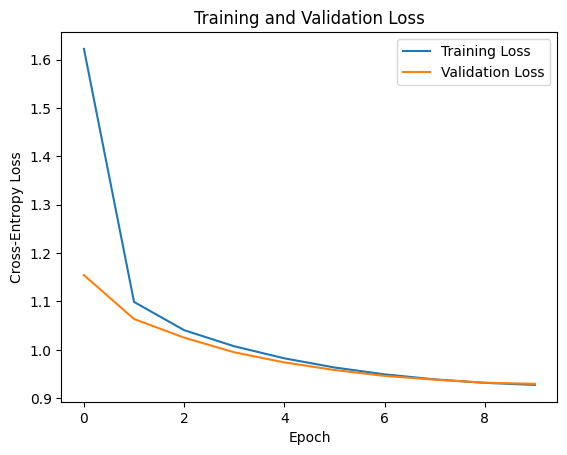

In [ ]:
train_losses = []
val_losses = []

if device.type == "cuda":
    torch.cuda.synchronize()

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

run_start = time.perf_counter()

total_train_tokens = 0
total_train_seconds = 0.0
nonfinite_steps = 0

checkpoint_dir = Path("task1_llm") / MEMBER_NAME / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
best_checkpoint_path = checkpoint_dir / f"task1_gpt_best_{run_timestamp}.pt"

for ep in range(epochs):
    if device.type == "cuda":
      torch.cuda.synchronize()
    epoch_train_start = time.perf_counter()
    epoch_train_tokens = 0
    model.train()
    total_loss = 0
    total_loss_tokens = 0
    total_grad_norm = 0
    max_grad_norm = 0
    num_train_batches = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        epoch_train_tokens += y.numel()

        logits = model(x)
        # combine B and T for cross-entropy loss
        loss = criterion(logits.view(-1, vocab_size), y.view(-1))
        # backpropagation and parameter update
        optimizer.zero_grad()
        loss.backward()
        gnorm = grad_norm(model)
        if not (math.isfinite(loss.item()) and math.isfinite(gnorm)):
            nonfinite_steps += 1
            log(
                f"Non-finite value detected: "
                f"loss={loss.item()}, grad_norm={gnorm}"
            )
            raise RuntimeError("Training stopped because loss or gradient became non-finite.")
        optimizer.step()
        scheduler.step()

        total_grad_norm += gnorm
        max_grad_norm = max(max_grad_norm, gnorm)
        num_train_batches += 1
        # loss for this epoch
        num_tokens = y.numel()
        total_loss += loss.item() * num_tokens
        total_loss_tokens += num_tokens

    avg_train_loss = total_loss / total_loss_tokens
    avg_grad_norm = total_grad_norm / num_train_batches
    train_losses.append(avg_train_loss)

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_seconds = time.perf_counter() - epoch_train_start
    total_train_seconds += epoch_train_seconds
    total_train_tokens += epoch_train_tokens
    epoch_tokens_per_sec = epoch_train_tokens / epoch_train_seconds

    model.eval()
    total_val_loss = 0
    total_val_tokens = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)

            loss = criterion(
                logits.view(-1, vocab_size),
                y.view(-1)
            )

            num_tokens = y.numel()
            total_val_loss += loss.item() * num_tokens
            total_val_tokens += num_tokens

    avg_val_loss = total_val_loss / total_val_tokens
    val_losses.append(avg_val_loss)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            {
                "epoch": ep + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_loss": avg_val_loss,
                "train_loss": avg_train_loss,
            },
            best_checkpoint_path
        )

        log(
            f"Saved new best checkpoint: "
            f"epoch={ep+1}, val_loss={avg_val_loss:.4f}, "
            f"path={best_checkpoint_path}"
        )

    log(
        f"Epoch {ep+1}/{epochs}, "
        f"Train Loss: {avg_train_loss:.4f}, "
        f"Val Loss: {avg_val_loss:.4f}, "
        f"Avg Grad Norm: {avg_grad_norm:.4f}, "
        f"Max Grad Norm: {max_grad_norm:.4f}, "
        f"Train Time: {epoch_train_seconds:.1f}s, "
        f"Tokens/s: {epoch_tokens_per_sec:.0f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()
    peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else:
    peak_memory_mb = 0.0

total_run_time = time.perf_counter() - run_start
overall_tokens_per_sec = total_train_tokens / total_train_seconds

log(f"Peak GPU Memory: {peak_memory_mb:.2f} MB")
log(f"Total Run Time: {total_run_time:.2f} s")
log(f"Overall Training Tokens/s: {overall_tokens_per_sec:.0f}")
log(f"Best Validation Loss: {best_val_loss:.4f}")
log(f"Best Checkpoint: {best_checkpoint_path}")
log(f"Non-finite training steps: {nonfinite_steps}")
log("Training completed successfully.")

log_file.close()

loss_curve_path = output_dir / f"loss_curve_{run_timestamp}.png"

plt.figure()
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.savefig(loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
manifest_dir = Path("reproducibility/manifests")
manifest_dir.mkdir(parents=True, exist_ok=True)

# Save exact package environment
environment_path = (
    manifest_dir
    / f"task1_{MEMBER_NAME}_environment_{run_timestamp}.txt"
)

with open(environment_path, "w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        text=True,
        check=True
    )

# Save manifest
manifest = {
    "task": "task1_llm",
    "member": MEMBER_NAME,
    "run_id": run_timestamp,

    "config_file": str(config_path),
    "raw_log": str(train_log_path),

    "best_checkpoint": str(best_checkpoint_path),
    "best_val_loss": float(best_val_loss),

    "metrics_report": str(
        Path("task1_llm")
        / MEMBER_NAME
        / "metrics_report.csv"
    ),

    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),

    "environment_file": str(environment_path)
}

manifest_path = (
    manifest_dir
    / f"task1_{MEMBER_NAME}_manifest_{run_timestamp}.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("Saved manifest:", manifest_path)
print("Saved environment:", environment_path)

Saved manifest: reproducibility/manifests/task1_jiayi_manifest_20261001_000337.json
Saved environment: reproducibility/manifests/task1_jiayi_environment_20261001_000337.txt


In [25]:
best_checkpoint_path = (
    Path("task1_llm")
    / MEMBER_NAME
    / "checkpoints"
    / "task1_gpt_best_20261001_000337.pt"
)


assert best_checkpoint_path.exists(), (
    f"Checkpoint not found: "
    f"{best_checkpoint_path}"
)


checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)


load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()


print("Checkpoint loaded successfully.")
print("Load result:", load_result)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Checkpoint train loss:",
    checkpoint["train_loss"]
)

print(
    "Checkpoint val loss:",
    checkpoint["val_loss"]
)

Checkpoint loaded successfully.
Load result: <All keys matched successfully>
Best epoch: 10
Checkpoint train loss: 0.9273615989492956
Checkpoint val loss: 0.9295939312745802


In [26]:
criterion = nn.CrossEntropyLoss()

x, y = next(
    iter(val_loader)
)

x = x.to(device)
y = y.to(device)


with torch.no_grad():
    logits = model(x)

    loss = criterion(
        logits.reshape(
            -1,
            vocab_size
        ),
        y.reshape(-1)
    )


print("x shape:", x.shape)
print("logits shape:", logits.shape)
print("Sanity loss:", loss.item())
print(
    "Loss finite:",
    torch.isfinite(loss).item()
)

x shape: torch.Size([32, 128])
logits shape: torch.Size([32, 128, 152])
Sanity loss: 0.9356637001037598
Loss finite: True


In [27]:
def perplexity(ce_loss):
    """exp(mean cross-entropy in nats)."""
    return math.exp(ce_loss)


def bits_per_char(ce_loss):
    """Cross-entropy converted from nats to bits."""
    return ce_loss / math.log(2)


def evaluate_loader(model, loader, device, vocab_size, desc="Evaluating"):
    model.eval()

    # reduction="sum":
    # first sum loss over every character,
    # then divide by total number of characters at the end.
    criterion = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0.0
    total_correct = 0
    total_tokens = 0

    with torch.no_grad():

        for x, y in tqdm(loader, desc=desc):

            x = x.to(device)
            y = y.to(device)

            logits = model(x)

            # logits:  [B, T, V]
            # targets: [B, T]

            loss_sum = criterion(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )

            total_loss += loss_sum.item()

            predictions = logits.argmax(dim=-1)

            total_correct += (
                predictions == y
            ).sum().item()

            total_tokens += y.numel()

    mean_ce_loss = total_loss / total_tokens
    top1_acc = total_correct / total_tokens

    return mean_ce_loss, top1_acc

In [28]:
val_ce, val_top1 = evaluate_loader(
    model,
    val_loader,
    device,
    vocab_size,
    desc="Validation"
)

print("Validation CE loss:", val_ce)
print("Validation Top-1 accuracy:", val_top1)

Validation:   0%|          | 0/2189 [00:00<?, ?it/s]

Validation CE loss: 0.9295939312796866
Validation Top-1 accuracy: 0.7061334288213036


In [29]:
train_ce, train_top1 = evaluate_loader(
    model,
    train_eval_loader,
    device,
    vocab_size,
    desc="Train"
)

print("Train CE loss:", train_ce)
print("Train Top-1 accuracy:", train_top1)

Train:   0%|          | 0/21908 [00:00<?, ?it/s]

Train CE loss: 0.9252886422143661
Train Top-1 accuracy: 0.707258950069824


In [30]:
train_ppl = perplexity(train_ce)
val_ppl = perplexity(val_ce)

train_bpc = bits_per_char(train_ce)
val_bpc = bits_per_char(val_ce)

generalization_gap = val_ce - train_ce


print(f"Train CE loss:          {train_ce:.6f}")
print(f"Validation CE loss:     {val_ce:.6f}")

print(f"Train perplexity:       {train_ppl:.6f}")
print(f"Validation perplexity:  {val_ppl:.6f}")

print(f"Train BPC:              {train_bpc:.6f}")
print(f"Validation BPC:         {val_bpc:.6f}")

print(f"Generalization gap:     {generalization_gap:.6f}")

print(f"Train top-1 accuracy:   {train_top1:.6f}")
print(f"Validation top-1 acc:   {val_top1:.6f}")

Train CE loss:          0.925289
Validation CE loss:     0.929594
Train perplexity:       2.522596
Validation perplexity:  2.533480
Train BPC:              1.334909
Validation BPC:         1.341121
Generalization gap:     0.004305
Train top-1 accuracy:   0.707259
Validation top-1 acc:   0.706133


In [32]:
@torch.no_grad()
def generate_temperature(prompt, max_new=100,  temperature=0.8):
    model.eval()
    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new):
        ids_cond = ids[:, -model.seq_len:]
        logits = model(ids_cond)
        next_logits = logits[:, -1, :]
        # scale logits
        next_logits = next_logits / temperature
        # convert logits to probabilities and sample one token
        probs = F.softmax(next_logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_token], dim=1)

    return decode(ids[0].tolist())

for temp in generation_temperatures:
    set_seed(SEED)
    print(f"\nTemperature = {temp}")
    print(generate_temperature(generation_prompt, generation_max_new, temperature=temp))


Temperature = 0.5
One day, they found a big mean to the park. He was so excited to see the cat were so excited. He loved the bunny and was very sad that he had a loud noise. H

Temperature = 0.8
One day, Chie ant, she saw a big picture of house. She was surprised that her mom with a long time to get for different to her smile. The kitten was small an

Temperature = 1.0
One day, Chie ant, she saw a big perplace little rewarded that she had together. She lissed her hand, the faster weak her pet raced of her toys. 

The doctor


In [33]:
model.eval()

with torch.no_grad():
    x, _ = next(iter(val_loader))
    _ = model(x[:1].to(device))

if torch.cuda.is_available():
    torch.cuda.synchronize()

print("Generation warm-up complete.")

Generation warm-up complete.


In [47]:
samples_per_temperature = 4

generation_results = []
generated_continuations = []

for temp_idx, temp in enumerate(generation_temperatures):

    for sample_idx in range(samples_per_temperature):

        # Reproducible, but different for every sample
        sample_seed = (
            SEED
            + temp_idx * samples_per_temperature
            + sample_idx
        )

        set_seed(sample_seed)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        generated_text = generate_temperature(
            generation_prompt,
            generation_max_new,
            temperature=temp
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time

        continuation = generated_text[
            len(generation_prompt):
        ]

        tokens_per_sec = (
            generation_max_new / elapsed
        )

        generation_results.append({
            "temperature": temp,
            "sample": sample_idx + 1,
            "seed": sample_seed,
            "prompt": generation_prompt,
            "max_new": generation_max_new,
            "generated_text": generated_text,
            "continuation": continuation,
            "generation_time_sec": elapsed,
            "generation_tokens_per_sec": tokens_per_sec
        })

        generated_continuations.append(
            continuation
        )

        print("=" * 70)
        print(
            f"Temperature: {temp} | "
            f"Sample: {sample_idx + 1}"
        )
        print(f"Seed: {sample_seed}")
        print(f"Time: {elapsed:.4f} sec")
        print(
            "Generation tokens/sec:",
            f"{tokens_per_sec:.2f}"
        )
        print()
        print(generated_text)
        print()

Temperature: 0.5 | Sample: 1
Seed: 4253
Time: 0.2639 sec
Generation tokens/sec: 568.29

One day, they found a big mean to the park. He was so excited to see the cat were so excited. He loved the bunny and was very sad that he had a loud noise. H

Temperature: 0.5 | Sample: 2
Seed: 4254
Time: 0.2529 sec
Generation tokens/sec: 593.11

One day, she saw a big boy named Timmy. Tim felt grew blocks and saw the street in the truck and put it on the forest, and the store was the truck was so kin

Temperature: 0.5 | Sample: 3
Seed: 4255
Time: 0.2512 sec
Generation tokens/sec: 597.17

One day, the bird said, "That is too bear something else. It is a farmer soup and waiting with his friends. When the bee grass and a mountain. We were so tha

Temperature: 0.5 | Sample: 4
Seed: 4256
Time: 0.2562 sec
Generation tokens/sec: 585.49

One day, she saw a big dad and a farmer dead and said, "Okay, Mommy. Let's play a tasty because it was time to go home."

Mommy and Dad said, "That's dinner 

Temperature:

In [48]:
total_generated_tokens = (
    generation_max_new
    * len(generation_temperatures)
    * samples_per_temperature
)

total_generation_time = sum(
    r["generation_time_sec"]
    for r in generation_results
)

generation_tokens_per_sec = (
    total_generated_tokens
    / total_generation_time
)

print(
    "Total generated samples:",
    len(generation_results)
)

print(
    "Total generated tokens:",
    total_generated_tokens
)

print(
    "Total generation time:",
    f"{total_generation_time:.4f} sec"
)

print(
    "Overall generation tokens/sec:",
    f"{generation_tokens_per_sec:.2f}"
)

Total generated samples: 12
Total generated tokens: 1800
Total generation time: 3.0717 sec
Overall generation tokens/sec: 585.99


In [49]:
def _units(text, unit):
    return text.split() if unit == "word" else list(text)


def _ngrams(tokens, n):
    return [
        tuple(tokens[i:i + n])
        for i in range(len(tokens) - n + 1)
    ]


def distinct_n(texts, n, unit="word"):
    """
    Unique n-grams / total n-grams,
    pooled over all generated samples.
    Higher = more diverse.
    """
    grams = [
        g
        for t in texts
        for g in _ngrams(_units(t, unit), n)
    ]

    return (
        len(set(grams)) / len(grams)
        if grams else 0.0
    )


def repeated_ngram_rate(texts, n=4, unit="word"):
    """
    Share of n-grams that already appeared earlier
    in the same sample, averaged over samples.
    Higher = more repetition.
    """
    rates = []

    for t in texts:
        grams = _ngrams(
            _units(t, unit),
            n
        )

        if grams:
            rates.append(
                1 - len(set(grams)) / len(grams)
            )

    return (
        sum(rates) / len(rates)
        if rates else 0.0
    )

In [50]:
distinct_1 = distinct_n(
    generated_continuations,
    n=1,
    unit="word"
)

distinct_2 = distinct_n(
    generated_continuations,
    n=2,
    unit="word"
)

distinct_3 = distinct_n(
    generated_continuations,
    n=3,
    unit="word"
)

repeat_4gram = repeated_ngram_rate(
    generated_continuations,
    n=4,
    unit="word"
)


print(f"Distinct-1:           {distinct_1:.6f}")
print(f"Distinct-2:           {distinct_2:.6f}")
print(f"Distinct-3:           {distinct_3:.6f}")
print(f"Repeated 4-gram rate: {repeat_4gram:.6f}")
print(
    f"Generation tokens/sec: "
    f"{generation_tokens_per_sec:.2f}"
)

Distinct-1:           0.531915
Distinct-2:           0.901099
Distinct-3:           0.974432
Repeated 4-gram rate: 0.000000
Generation tokens/sec: 585.99


In [39]:
RUN_ID = "20261001_000337"

train_log_path = Path(
    f"reproducibility/raw_logs/"
    f"task1_jiayi_train_{RUN_ID}.log"
)

print("Log:", train_log_path)
print("Exists:", train_log_path.exists())

Log: reproducibility/raw_logs/task1_jiayi_train_20261001_000337.log
Exists: True


In [51]:
log_text = train_log_path.read_text()

parameter_count = int(
    re.search(
        r"Parameter count: (\d+)",
        log_text
    ).group(1)
)

training_tokens_per_sec = float(
    re.search(
        r"Overall Training Tokens/s: ([\d.]+)",
        log_text
    ).group(1)
)

peak_gpu_memory_mb = float(
    re.search(
        r"Peak GPU Memory: ([\d.]+) MB",
        log_text
    ).group(1)
)

total_training_time_sec = float(
    re.search(
        r"Total Run Time: ([\d.]+) s",
        log_text
    ).group(1)
)

nonfinite_steps = int(
    re.search(
        r"Non-finite training steps: (\d+)",
        log_text
    ).group(1)
)

print("Parameter count:", parameter_count)
print("Training tokens/sec:", training_tokens_per_sec)
print("Peak GPU memory (MB):", peak_gpu_memory_mb)
print("Total training time (sec):", total_training_time_sec)
print("Non-finite training steps:", nonfinite_steps)

Parameter count: 452248
Training tokens/sec: 572170.0
Peak GPU memory (MB): 123.55
Total training time (sec): 1614.17
Non-finite training steps: 0


In [52]:
grad_matches = re.findall(
    r"Avg Grad Norm: ([\d.]+), "
    r"Max Grad Norm: ([\d.]+)",
    log_text
)

avg_grad_norms = [
    float(avg)
    for avg, max_ in grad_matches
]

max_grad_norms = [
    float(max_)
    for avg, max_ in grad_matches
]

mean_grad_norm = sum(avg_grad_norms) / len(avg_grad_norms)
max_grad_norm_overall = max(max_grad_norms)

print("Epoch avg grad norms:", avg_grad_norms)
print("Mean gradient norm:", mean_grad_norm)
print("Maximum gradient norm:", max_grad_norm_overall)

Epoch avg grad norms: [0.8783, 0.9039, 0.8435, 0.8101, 0.8004, 0.8067, 0.8237, 0.8464, 0.8693, 0.8886]
Mean gradient norm: 0.84709
Maximum gradient norm: 2.9612


In [53]:
evaluation_metrics = {
    "train_cross_entropy": train_ce,
    "validation_cross_entropy": val_ce,

    "train_perplexity": train_ppl,
    "validation_perplexity": val_ppl,

    "train_bits_per_character": train_bpc,
    "validation_bits_per_character": val_bpc,

    "generalization_gap": generalization_gap,

    "train_top1_accuracy": train_top1,
    "validation_top1_accuracy": val_top1,
    "distinct_1": distinct_1,
    "distinct_2": distinct_2,
    "distinct_3": distinct_3,
    "repeated_4gram_rate": repeat_4gram,

    "parameter_count": parameter_count,

    "mean_gradient_norm": mean_grad_norm,
    "max_gradient_norm": max_grad_norm_overall,
    "nonfinite_training_steps": nonfinite_steps,

    "training_tokens_per_sec": training_tokens_per_sec,
    "generation_tokens_per_sec": generation_tokens_per_sec,

    "peak_gpu_memory_mb": peak_gpu_memory_mb,
    "total_training_time_sec": total_training_time_sec,
}

evaluation_metrics

{'train_cross_entropy': 0.9252886422143661,
 'validation_cross_entropy': 0.9295939312796866,
 'train_perplexity': 2.5225962830611453,
 'validation_perplexity': 2.533480201651093,
 'train_bits_per_character': 1.3349093355135484,
 'validation_bits_per_character': 1.3411205546976797,
 'generalization_gap': 0.004305289065320461,
 'train_top1_accuracy': 0.707258950069824,
 'validation_top1_accuracy': 0.7061334288213036,
 'distinct_1': 0.5319148936170213,
 'distinct_2': 0.9010989010989011,
 'distinct_3': 0.9744318181818182,
 'repeated_4gram_rate': 0.0,
 'parameter_count': 452248,
 'mean_gradient_norm': 0.84709,
 'max_gradient_norm': 2.9612,
 'nonfinite_training_steps': 0,
 'training_tokens_per_sec': 572170.0,
 'generation_tokens_per_sec': 585.9895756275953,
 'peak_gpu_memory_mb': 123.55,
 'total_training_time_sec': 1614.17}

In [56]:
device_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

metrics_rows = [
    ("run_name", "task1_gpt_best_20261001_000337"),
    ("checkpoint", str(best_checkpoint_path)),
    ("best_epoch", checkpoint["epoch"]),

    ("train_cross_entropy", train_ce),
    ("val_cross_entropy", val_ce),

    ("val_perplexity", val_ppl),
    ("val_bits_per_char", val_bpc),
    ("train_perplexity", train_ppl),
    ("train_bits_per_char", train_bpc),

    ("generalization_gap", generalization_gap),

    ("train_top1_acc", train_top1),
    ("val_top1_acc", val_top1),

    ("distinct_1", distinct_1),
    ("distinct_2", distinct_2),
    ("distinct_3", distinct_3),
    ("repeated_4gram_rate", repeat_4gram),

    ("grad_norm_mean", mean_grad_norm),
    ("grad_norm_max", max_grad_norm_overall),
    ("nan_inf_steps", nonfinite_steps),

    # training-time logged value, different from
    # frozen-checkpoint full-train evaluation above
    ("final_logged_train_loss", checkpoint["train_loss"]),

    ("parameters", parameter_count),

    ("train_tokens_per_s", training_tokens_per_sec),
    ("gen_tokens_per_s", generation_tokens_per_sec),

    ("total_train_time_s", total_training_time_sec),
    ("total_train_time_min", total_training_time_sec / 60),

    ("epochs", config["training"]["epochs"]),

    ("peak_gpu_mem_mb", peak_gpu_memory_mb),
    ("device", device_name),
]

metrics_df = pd.DataFrame(
    metrics_rows,
    columns=["metric", "value"]
)

display(metrics_df)

,metric,value
0,run_name,task1_gpt_best_20261001_000337
1,checkpoint,task1_llm/jiayi/checkpoints/task1_gpt_best_202...
2,best_epoch,10
3,train_cross_entropy,0.925289
4,val_cross_entropy,0.929594
5,val_perplexity,2.53348
6,val_bits_per_char,1.341121
7,train_perplexity,2.522596
8,train_bits_per_char,1.334909
9,generalization_gap,0.004305


In [57]:
metrics_path = (
    Path("task1_llm")
    / MEMBER_NAME
    / "metrics_report.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

print("Saved:", metrics_path)

Saved: task1_llm/jiayi/metrics_report.csv


In [72]:
outputs_dir = (
    Path("task1_llm")
    / MEMBER_NAME
    / "outputs"
)

outputs_dir.mkdir(
    parents=True,
    exist_ok=True
)

generation_json_path = (
    outputs_dir
    / "generation_samples.json"
)

with open(
    generation_json_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        generation_results,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Saved:", generation_json_path)

Saved: task1_llm/jiayi/outputs/generation_samples.json


In [73]:
generation_txt_path = (
    outputs_dir
    / "generation_samples.txt"
)

with open(
    generation_txt_path,
    "w",
    encoding="utf-8"
) as f:

    for result in generation_results:

        f.write("=" * 70 + "\n")

        f.write(
            f"Temperature: "
            f"{result['temperature']}\n"
        )

        f.write(
            f"Sample: "
            f"{result['sample']}\n"
        )

        f.write(
            f"Seed: "
            f"{result['seed']}\n"
        )

        f.write(
            f"Generation time: "
            f"{result['generation_time_sec']:.4f} sec\n"
        )

        f.write(
            f"Generation tokens/sec: "
            f"{result['generation_tokens_per_sec']:.2f}\n\n"
        )

        f.write(
            result["generated_text"]
            + "\n\n"
        )

print("Saved:", generation_txt_path)

Saved: task1_llm/jiayi/outputs/generation_samples.txt
